# 06 – Trouver le meilleur modèle de machine learning

## Leçon 1 – Pourquoi comparer plusieurs modèles ?

Dans le projet 13, on était allés directement au `HistGradientBoostingClassifier`. C'est souvent le bon choix pour des données en tableau, mais un vrai data scientist **le vérifie**. Il n'existe pas de « meilleur modèle » universel : ça dépend des données (c'est le *no free lunch theorem*).

On va comparer **4 familles** de modèles, du plus simple au plus puissant :

| Modèle | Idée | Analogie |
|---|---|---|
| **Régression logistique** | une somme pondérée des variables, transformée en probabilité | une formule de scoring avec des coefficients |
| **Arbre de décision** | une suite de questions oui/non | un organigramme de décision |
| **Forêt aléatoire** (*random forest*) | des centaines d'arbres entraînés **indépendamment** sur des échantillons différents, puis on fait **la moyenne** | demander l'avis à 100 experts et faire la moyenne |
| **Gradient boosting** (HGB) | des centaines de petits arbres entraînés **à la suite**, chacun corrigeant les erreurs des précédents | un expert qui affine sa prévision étape par étape |

La forêt aléatoire, c'est le **bagging** (moyenne d'arbres indépendants). Le gradient boosting, c'est le **boosting** (arbres en série). Ce sont les deux grandes familles d'« ensembles d'arbres », et des questions classiques de certification ML !

**Protocole :** tous entraînés sur 2016-2020, comparés sur la validation 2021-2022, avec la même métrique. Le test 2023-2025 reste **sous clé** jusqu'au choix final.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.inspection import permutation_importance

FEATURES = [
    # calendrier
    "mois", "jour_annee", "jour_semaine", "week_end",
    # météo du jour
    "pluie", "temp_moy", "temp_max", "vent_moy", "humidite_moy", "evapo", "humidite_sol",
    # météo des jours passés
    "pluie_7j", "pluie_30j", "evapo_30j", "temp_max_7j", "humidite_sol_7j",
    "bilan_hydrique_30j", "jours_sans_pluie", "vent_fort",
    # historique de feux (décalé d'un jour)
    "feux_commune_365j", "taux_feu_commune", "feux_dept_veille", "feux_zone_veille",
    # géographie et population
    "lat", "lon", "log_densite",
]

df = pd.read_parquet("../data/processed/features_med.parquet", columns=["code", "dept", "jour", "feu"] + FEATURES)
df["annee"] = df["jour"].dt.year
print(df.shape, "-", len(FEATURES), "features")

(12803765, 31) - 26 features


## Étape 1 – Le découpage et la baseline à battre

In [2]:
train = df[df["annee"] <= 2020]
valid = df[df["annee"].between(2021, 2022)]
y_valid = valid["feu"].values

def part_feux_couverte(y, score, part=0.05):
    n = int(len(y) * part)
    ordre = np.argsort(-np.asarray(score))[:n]
    return np.asarray(y)[ordre].sum() / np.sum(y)

def baseline_lissee(historique, cible, k=200):
    stats = historique.groupby(["code", "mois"]).agg(feux=("feu", "sum"), jours=("feu", "size"), dept=("dept", "first"))
    stats = stats.join(historique.groupby(["dept", "mois"], observed=True)["feu"].mean().rename("taux_dm"), on=["dept", "mois"])
    lisse = ((stats["feux"] + k * stats["taux_dm"]) / (stats["jours"] + k)).rename("score")
    return cible[["code", "mois"]].merge(lisse, left_on=["code", "mois"], right_index=True, how="left")["score"].values

score_baseline = baseline_lissee(train, valid)
resultats = [{"modèle": "Baseline lissée commune × mois",
              "PR-AUC": average_precision_score(y_valid, score_baseline),
              "top 5 %": part_feux_couverte(y_valid, score_baseline), "secondes": 0}]
print(resultats[0])

{'modèle': 'Baseline lissée commune × mois', 'PR-AUC': 0.015749538202807098, 'top 5 %': np.float64(0.3331402085747393), 'secondes': 0}


**Attendu :** PR-AUC ≈ 0,0157 et top 5 % ≈ 33 % (notebook 05).

`np.argsort(-score)` donne les positions des lignes triées du plus grand au plus petit score. C'est bien plus rapide qu'un `sort_values` sur un DataFrame de 2,5 millions de lignes.

## Leçon 2 – 6,4 millions de lignes : sous-échantillonner les « non-feux »

Le train contient 6,4 millions de lignes, dont seulement **7 815 feux**. Les 6,4 millions de « non-feux » se ressemblent énormément (un jour d'hiver pluvieux en Lozère ressemble à un autre). En garder 1 sur 10 suffit à apprendre ce qu'est un jour « normal ».

**Sous-échantillonnage des négatifs :** on garde **100 % des feux** et **10 % des non-feux** tirés au hasard → ≈ 650 000 lignes, **10 fois plus rapide**.

⚠️ Mais le modèle verrait alors un taux de feu 10 fois trop élevé (1,2 % au lieu de 0,12 %), et ses probabilités seraient fausses. On corrige avec des **poids** : chaque non-feu gardé compte pour **10** (il représente les 9 qu'on a écartés). Le modèle « voit » ainsi les bonnes proportions.

C'est une technique standard dès que les données sont volumineuses et déséquilibrées (détection de fraude, clics publicitaires…).

In [3]:
hasard = np.random.default_rng(42)
garde = (train["feu"] == 1) | (hasard.random(len(train)) < 0.10)
echantillon = train[garde]
poids = np.where(echantillon["feu"] == 1, 1, 10)

X_ech, y_ech = echantillon[FEATURES], echantillon["feu"]
X_valid = valid[FEATURES]
print(f"{len(echantillon):,} lignes ({echantillon['feu'].sum()} feux) au lieu de {len(train):,}")
print(f"taux de feu pondéré : {np.average(y_ech, weights=poids):.3%}  (vrai taux du train : {train['feu'].mean():.3%})")

646,519 lignes (7815 feux) au lieu de 6,403,635
taux de feu pondéré : 0.122%  (vrai taux du train : 0.122%)


Le taux de feu **pondéré** retombe bien sur le vrai taux du train (≈ 0,12 %).

**Vérifions que l'échantillonnage ne coûte presque rien en qualité :** on entraîne le même gradient boosting sur le train **complet** puis sur l'échantillon (⏱️ ≈ 3 min pour le complet).

In [4]:
def entrainer_et_evaluer(nom, modele, X, y, **fit_params):
    debut = time.time()
    modele.fit(X, y, **fit_params)
    proba = modele.predict_proba(X_valid)[:, 1]
    duree = time.time() - debut
    resultats.append({"modèle": nom, "PR-AUC": average_precision_score(y_valid, proba),
                      "top 5 %": part_feux_couverte(y_valid, proba), "secondes": round(duree)})
    print(f"{nom:45} PR-AUC = {resultats[-1]['PR-AUC']:.4f}   top 5 % → {resultats[-1]['top 5 %']:.0%}   ({duree:.0f} s)")
    return proba

REGLAGES_TEST = dict(learning_rate=0.03, max_iter=300, early_stopping=False, max_leaf_nodes=7, random_state=42)

_ = entrainer_et_evaluer("HGB – train complet (6,4 M lignes)",
                         HistGradientBoostingClassifier(min_samples_leaf=1000, **REGLAGES_TEST),
                         train[FEATURES], train["feu"])
_ = entrainer_et_evaluer("HGB – échantillon pondéré (0,65 M lignes)",
                         HistGradientBoostingClassifier(min_samples_leaf=100, **REGLAGES_TEST),
                         X_ech, y_ech, sample_weight=poids)

HGB – train complet (6,4 M lignes)            PR-AUC = 0.0198   top 5 % → 46%   (238 s)


HGB – échantillon pondéré (0,65 M lignes)     PR-AUC = 0.0188   top 5 % → 46%   (28 s)


**Attendu :** des scores proches (PR-AUC ≈ 0,020 sur le train complet, ≈ 0,019 sur l'échantillon, 46 % des feux dans le top 5 % dans les deux cas), mais ≈ 30 s au lieu de ≈ 4 min. On perd un tout petit peu de PR-AUC, mais on gagne un facteur 8 en temps : ça va nous permettre de tester beaucoup plus de modèles et de réglages.

Pourquoi `min_samples_leaf` passe de 1 000 à 100 ? C'est le nombre minimum de **lignes** par feuille ; l'échantillon a 10 fois moins de lignes, on divise donc aussi par 10 pour garder des feuilles de « taille » comparable.

👉 À partir de maintenant, **tous les modèles s'entraînent sur l'échantillon pondéré**.

## Étape 2 – La régression logistique

Le modèle linéaire de référence : `score = a₁ × humidite_sol + a₂ × vent_moy + … + b`, puis une fonction en « S » (la sigmoïde) transforme ce score en probabilité entre 0 et 1.

Elle a besoin que les variables soient **à la même échelle** (sinon la population, en milliers, écrase l'humidité des sols, entre 0 et 1). `StandardScaler` centre et réduit chaque variable (moyenne 0, écart-type 1). `make_pipeline` enchaîne les deux étapes en un seul objet.

In [5]:
proba_logistique = entrainer_et_evaluer(
    "Régression logistique",
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    X_ech, y_ech, logisticregression__sample_weight=poids,
)

Régression logistique                         PR-AUC = 0.0178   top 5 % → 36%   (3 s)


`logisticregression__sample_weight` : dans un pipeline, on doit préciser **à quelle étape** on passe les poids (nom de l'étape + deux tirets bas).

## Étape 3 – Un arbre de décision seul

In [6]:
_ = entrainer_et_evaluer(
    "Arbre de décision (profondeur 8)",
    DecisionTreeClassifier(max_depth=8, min_samples_leaf=500, random_state=42),
    X_ech, y_ech, sample_weight=poids,
)

Arbre de décision (profondeur 8)              PR-AUC = 0.0153   top 5 % → 43%   (9 s)


## Étape 4 – La forêt aléatoire

Chaque arbre voit un **échantillon tiré au hasard** des lignes, et à chaque question seulement une **partie des variables** (`max_features="sqrt"` : √26 ≈ 5 variables tirées au hasard). Les arbres sont donc tous un peu différents. Leur **moyenne** est beaucoup plus stable qu'un arbre seul.

`n_jobs=-1` = utiliser **tous les cœurs** du processeur (8 sur ton Mac) : les arbres sont indépendants, on peut les construire en parallèle. ⏱️ ≈ 2-3 min.

In [7]:
proba_foret = entrainer_et_evaluer(
    "Forêt aléatoire (150 arbres)",
    RandomForestClassifier(n_estimators=150, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=42),
    X_ech, y_ech, sample_weight=poids,
)

Forêt aléatoire (150 arbres)                  PR-AUC = 0.0206   top 5 % → 43%   (168 s)


## Étape 5 – Le gradient boosting : par défaut, puis réglé

Rappel du projet 13 : les réglages par défaut **surapprennent** (des feuilles trop petites qui collent au bruit). On teste une petite **grille** sur deux réglages clés :
- `max_leaf_nodes` : nombre de feuilles par arbre (complexité de chaque arbre) ;
- `min_samples_leaf` : nombre minimum de lignes par feuille (une feuille doit s'appuyer sur assez d'exemples).

⏱️ 6 combinaisons × ≈ 1 min.

In [8]:
_ = entrainer_et_evaluer("HGB – réglages par défaut", HistGradientBoostingClassifier(random_state=42),
                         X_ech, y_ech, sample_weight=poids)

grille = []
for feuilles in [7, 15]:
    for min_feuille in [100, 1000, 5000]:
        m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, early_stopping=False,
                                           max_leaf_nodes=feuilles, min_samples_leaf=min_feuille, random_state=42)
        m.fit(X_ech, y_ech, sample_weight=poids)
        p = m.predict_proba(X_valid)[:, 1]
        grille.append({"max_leaf_nodes": feuilles, "min_samples_leaf": min_feuille,
                       "PR-AUC": average_precision_score(y_valid, p), "top 5 %": part_feux_couverte(y_valid, p)})
        print(grille[-1])

grille = pd.DataFrame(grille)
grille.pivot(index="max_leaf_nodes", columns="min_samples_leaf", values="PR-AUC").round(4)

HGB – réglages par défaut                     PR-AUC = 0.0136   top 5 % → 42%   (4 s)


{'max_leaf_nodes': 7, 'min_samples_leaf': 100, 'PR-AUC': 0.018083380778201593, 'top 5 %': np.float64(0.4559675550405562)}


{'max_leaf_nodes': 7, 'min_samples_leaf': 1000, 'PR-AUC': 0.020404206975693357, 'top 5 %': np.float64(0.45712630359212053)}


{'max_leaf_nodes': 7, 'min_samples_leaf': 5000, 'PR-AUC': 0.0226569218183187, 'top 5 %': np.float64(0.466396292004635)}


{'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'PR-AUC': 0.018332673547508286, 'top 5 %': np.float64(0.45307068366164543)}


{'max_leaf_nodes': 15, 'min_samples_leaf': 1000, 'PR-AUC': 0.021341954915291773, 'top 5 %': np.float64(0.462630359212051)}


{'max_leaf_nodes': 15, 'min_samples_leaf': 5000, 'PR-AUC': 0.02328831459305662, 'top 5 %': np.float64(0.46523754345307067)}


min_samples_leaf,100,1000,5000
max_leaf_nodes,,,
7,0.0181,0.0204,0.0227
15,0.0183,0.0213,0.0233


**Lecture :** plus `min_samples_leaf` est grand, meilleure est la validation (0,018 → 0,023). Avec seulement ≈ 7 800 feux dans le train, des feuilles de 100 lignes apprennent du **bruit** ; des feuilles de 5 000 lignes (pondérées, soit ≈ 50 000 jours réels) capturent des **régularités**. Le nombre de feuilles compte beaucoup moins.

On retient la meilleure combinaison.

In [9]:
meilleur = grille.sort_values("PR-AUC", ascending=False).iloc[0]
REGLAGES = dict(learning_rate=0.05, max_iter=500, early_stopping=False,
                max_leaf_nodes=int(meilleur["max_leaf_nodes"]), min_samples_leaf=int(meilleur["min_samples_leaf"]),
                random_state=42)
print(REGLAGES)

modele = HistGradientBoostingClassifier(**REGLAGES)
proba_hgb = entrainer_et_evaluer("HGB – réglé", modele, X_ech, y_ech, sample_weight=poids)

{'learning_rate': 0.05, 'max_iter': 500, 'early_stopping': False, 'max_leaf_nodes': 15, 'min_samples_leaf': 5000, 'random_state': 42}


HGB – réglé                                   PR-AUC = 0.0233   top 5 % → 47%   (51 s)


## Étape 6 – Le match

In [10]:
tableau = pd.DataFrame(resultats)
tableau["× hasard"] = tableau["PR-AUC"] / y_valid.mean()
tableau["vs baseline"] = tableau["PR-AUC"] / tableau.loc[0, "PR-AUC"] - 1
tableau.sort_values("PR-AUC", ascending=False).style.format(
    {"PR-AUC": "{:.4f}", "top 5 %": "{:.0%}", "× hasard": "{:.1f}", "vs baseline": "{:+.0%}"})

,modèle,PR-AUC,top 5 %,secondes,× hasard,vs baseline
7,HGB – réglé,0.0233,47%,51,17.3,+48%
5,Forêt aléatoire (150 arbres),0.0206,43%,168,15.2,+31%
1,"HGB – train complet (6,4 M lignes)",0.0198,46%,238,14.7,+26%
2,"HGB – échantillon pondéré (0,65 M lignes)",0.0188,46%,28,13.9,+19%
3,Régression logistique,0.0178,36%,3,13.2,+13%
0,Baseline lissée commune × mois,0.0157,33%,0,11.7,+0%
4,Arbre de décision (profondeur 8),0.0153,43%,9,11.4,-3%
6,HGB – réglages par défaut,0.0136,42%,4,10.0,-14%


**Lecture :**
- Presque tous les modèles battent la baseline. Combiner météo, géographie et historique paie. Exceptions : l'**arbre seul** et le **HGB avec ses réglages par défaut** (−14 % : il surapprend, comme dans le projet 13).
- La **régression logistique** fait une PR-AUC honorable (+13 %), mais elle trie moins bien les 5 % de lignes les plus risquées (36 % des feux contre 46-47 % pour les ensembles d'arbres). Elle ne peut pas représenter les **interactions** (« sec ET en été ET commune qui brûle souvent »), seulement des effets qui s'additionnent.
- L'**arbre seul** est instable : un seul organigramme ne capte pas toute la complexité.
- La **forêt aléatoire** est très bonne (+31 %), mais **lente** (≈ 3 min) et un peu moins bonne sur le top 5 % (43 %).
- Le **gradient boosting réglé** est le meilleur sur les deux indicateurs : PR-AUC **0,0233 (+48 % vs la baseline)** et **47 % des feux** dans le top 5 %, en moins d'une minute. 🏆

👉 Même conclusion que dans le projet 13, mais cette fois **démontrée**. Remarque aussi l'écart entre « HGB par défaut » et « HGB réglé » : le **réglage** compte autant que le **choix** du modèle.

## Étape 7 – Les courbes précision-rappel

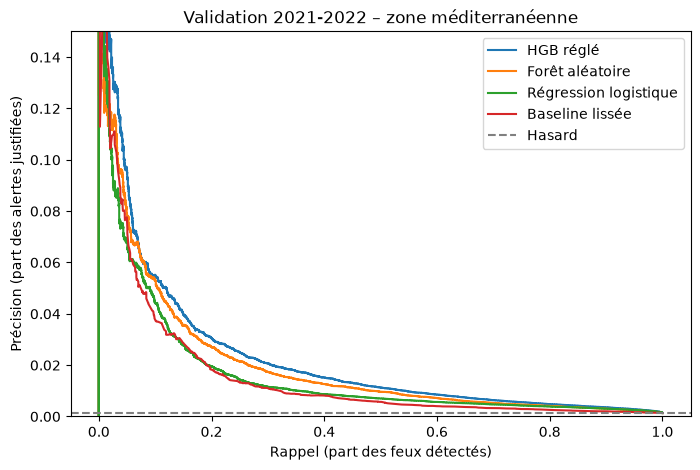

In [11]:
plt.figure(figsize=(8, 5))
for nom, score in [("HGB réglé", proba_hgb), ("Forêt aléatoire", proba_foret),
                   ("Régression logistique", proba_logistique), ("Baseline lissée", score_baseline)]:
    precision, rappel, _ = precision_recall_curve(y_valid, score)
    plt.plot(rappel, precision, label=nom)
plt.axhline(y_valid.mean(), color="grey", linestyle="--", label="Hasard")
plt.xlabel("Rappel (part des feux détectés)")
plt.ylabel("Précision (part des alertes justifiées)")
plt.title("Validation 2021-2022 – zone méditerranéenne")
plt.ylim(0, 0.15)
plt.legend()
plt.show()

## Étape 8 – Quelles variables comptent ?

**Importance par permutation** (comme dans le projet 13) : on mélange une colonne au hasard et on mesure la baisse de PR-AUC. Plus ça baisse, plus la variable était utile.

Sur 2,5 millions de lignes × 26 variables × 3 répétitions, ce serait long : on le fait sur un **échantillon de 30 %** de la validation (≈ 770 000 lignes, ≈ 1 000 feux).

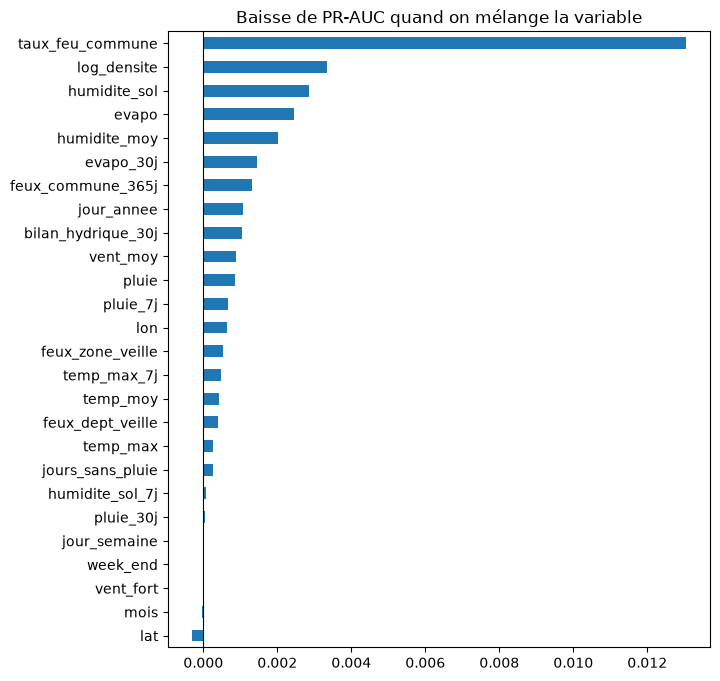

taux_feu_commune     0.0130
log_densite          0.0034
humidite_sol         0.0029
evapo                0.0024
humidite_moy         0.0020
evapo_30j            0.0015
feux_commune_365j    0.0013
jour_annee           0.0011
dtype: float64

In [12]:
echantillon_valid = valid.sample(frac=0.30, random_state=42)
imp = permutation_importance(modele, echantillon_valid[FEATURES], echantillon_valid["feu"],
                             scoring="average_precision", n_repeats=3, random_state=42, n_jobs=1)
importances = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

importances.plot(kind="barh", figsize=(7, 8), title="Baisse de PR-AUC quand on mélange la variable")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()
importances.sort_values(ascending=False).head(8).round(4)

**Lecture :** l'**historique de la commune** (`taux_feu_commune`) arrive en tête : *où* reste l'information n°1. Viennent ensuite la **densité de population** et des variables de **sécheresse** (humidité des sols, évapotranspiration). Les variables « jour du calendrier » comptent peu : la météo dit déjà mieux que le calendrier si la végétation est sèche.

Une variable à importance ≈ 0 n'est pas forcément inutile : une autre variable très proche peut porter la même information (ex. `pluie_7j` et `pluie_30j`).

## Étape 9 – Le test final (on ouvre le coffre 🔓)

On réentraîne le modèle réglé sur **2016-2022** (train + validation, toujours échantillonné et pondéré), puis on évalue **une seule fois** sur 2023-2025. La baseline est recalculée de la même façon sur 2016-2022.

In [13]:
historique = df[df["annee"] <= 2022]
test = df[df["annee"] >= 2023]

garde = (historique["feu"] == 1) | (np.random.default_rng(42).random(len(historique)) < 0.10)
ech_final = historique[garde]
poids_final = np.where(ech_final["feu"] == 1, 1, 10)

modele_final = HistGradientBoostingClassifier(**REGLAGES)
modele_final.fit(ech_final[FEATURES], ech_final["feu"], sample_weight=poids_final)

proba_test = modele_final.predict_proba(test[FEATURES])[:, 1]
baseline_test = baseline_lissee(historique, test)
y_test = test["feu"].values

print(f"Taux de feu du test : {y_test.mean():.3%}\n")
print(f"{'':10} {'PR-AUC':>8} {'top 5 %':>8}")
print(f"{'Baseline':10} {average_precision_score(y_test, baseline_test):>8.4f} {part_feux_couverte(y_test, baseline_test):>8.0%}")
print(f"{'Modèle':10} {average_precision_score(y_test, proba_test):>8.4f} {part_feux_couverte(y_test, proba_test):>8.0%}")

Taux de feu du test : 0.108%

             PR-AUC  top 5 %


Baseline     0.0114      33%


Modèle       0.0187      44%


**Résultat :** sur le test, le modèle atteint une PR-AUC de **0,0187 contre 0,0114** pour la baseline (**+64 %**), et couvre **44 % des feux** en surveillant 5 % des lignes, contre 33 %. Le test est un peu plus difficile que la validation (taux de feu 0,108 % contre 0,135 %), mais l'écart avec la baseline se maintient : le modèle n'a pas « appris par cœur » la validation.

## Étape 10 – Résultats par année et par département

In [14]:
lignes = []
for annee in [2023, 2024, 2025]:
    m = (test["annee"] == annee).values
    lignes.append({"année": annee, "taux de feu": y_test[m].mean(),
                   "PR-AUC baseline": average_precision_score(y_test[m], baseline_test[m]),
                   "PR-AUC modèle": average_precision_score(y_test[m], proba_test[m]),
                   "top 5 % baseline": part_feux_couverte(y_test[m], baseline_test[m]),
                   "top 5 % modèle": part_feux_couverte(y_test[m], proba_test[m])})
pd.DataFrame(lignes).style.format({"taux de feu": "{:.3%}", "PR-AUC baseline": "{:.4f}", "PR-AUC modèle": "{:.4f}",
                                   "top 5 % baseline": "{:.0%}", "top 5 % modèle": "{:.0%}"})

,année,taux de feu,PR-AUC baseline,PR-AUC modèle,top 5 % baseline,top 5 % modèle
0,2023,0.143%,0.0092,0.0172,27%,40%
1,2024,0.080%,0.0132,0.0167,40%,47%
2,2025,0.101%,0.0143,0.0238,36%,46%


In [15]:
lignes = []
for dept in sorted(test["dept"].unique()):
    m = (test["dept"] == dept).values
    lignes.append({"dept": dept, "feux": int(y_test[m].sum()),
                   "top 5 % baseline": part_feux_couverte(y_test[m], baseline_test[m]),
                   "top 5 % modèle": part_feux_couverte(y_test[m], proba_test[m])})
par_dept = pd.DataFrame(lignes).set_index("dept")
par_dept["gain"] = par_dept["top 5 % modèle"] - par_dept["top 5 % baseline"]
par_dept.sort_values("gain").style.format({"top 5 % baseline": "{:.0%}", "top 5 % modèle": "{:.0%}", "gain": "{:+.0%}"})

,feux,top 5 % baseline,top 5 % modèle,gain
dept,,,,
04,97,30%,31%,+1%
13,728,36%,41%,+5%
2A,275,32%,37%,+5%
84,151,23%,28%,+5%
11,469,36%,41%,+6%
06,243,23%,30%,+8%
66,173,20%,29%,+9%
83,537,17%,28%,+11%
2B,438,25%,37%,+13%


Le modèle bat la baseline **chaque année** (2023, 2024, 2025).

Ici le « top 5 % » est calculé **à l'intérieur de chaque département** : *« si un département surveille ses 5 % de communes × jours les plus risqués, quelle part de ses feux couvre-t-il ? »*

**Le modèle gagne dans les 15 départements.** Le gain est faible là où la baseline est déjà bonne (Alpes-de-Haute-Provence, Bouches-du-Rhône, Aude), et énorme dans les départements où les feux sont dispersés et l'historique pauvre : **Lozère 15 % → 39 %**, **Ardèche 13 % → 36 %**, Gard, Drôme. C'est là que la météo (humidité des sols, sécheresse) apporte le plus : quand on ne peut pas s'appuyer sur « cette commune brûle souvent », il faut savoir *quand* la végétation est sèche.

## Étape 11 – Sauvegarder les prédictions et le modèle

Nouveau : on **sauvegarde le modèle entraîné** avec `joblib` (installé avec scikit-learn). Les notebooks suivants pourront le recharger sans le réentraîner. C'est aussi la première étape d'une **mise en production** : dans le cloud, on déploie exactement ce genre de fichier derrière une API.

In [16]:
import joblib

predictions = test[["code", "dept", "jour", "feu"]].copy()
predictions["proba_modele"] = proba_test.astype("float32")
predictions["score_baseline"] = baseline_test.astype("float32")
predictions.to_parquet("../data/processed/predictions_test.parquet", index=False)

joblib.dump({"modele": modele_final, "features": FEATURES, "reglages": REGLAGES}, "../data/processed/modele_2016_2022.joblib")
tableau.to_csv("../data/processed/comparaison_modeles.csv", index=False)
print("sauvegardé")

sauvegardé


## 🎯 À toi de jouer

Les 10 lignes du test avec la plus forte probabilité : quelles communes, quels jours ? Y a-t-il eu un feu ?

*(indice : `predictions.sort_values(...).head(10)` puis un `merge` avec `communes_med.csv` pour avoir les noms)*

In [17]:
# à toi

<details><summary>Correction</summary>

```python
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str})
top10 = predictions.sort_values("proba_modele", ascending=False).head(10)
top10.merge(communes[["code", "nom"]], on="code")[["nom", "dept", "jour", "proba_modele", "feu"]]
```
</details>

## Récap

1. **4 familles comparées** avec le même protocole : régression logistique, arbre, forêt aléatoire (*bagging*), gradient boosting (*boosting*).
2. **Sous-échantillonnage des négatifs + poids** : 10× plus rapide, qualité quasi identique, probabilités correctes.
3. Le **gradient boosting réglé** gagne ; le réglage (`min_samples_leaf` élevé) compte autant que le choix du modèle.
4. Sur le **test 2023-2025**, jamais vu, le modèle bat la baseline chaque année.
5. Le modèle est **sauvegardé** (`joblib`) pour la suite.

**Prochaine étape (07) :** les cartes, et vérifier si les probabilités sont bien calibrées.